<a href="https://colab.research.google.com/github/hilalkaynarcali/goruntu-isleme/blob/main/DFT_frekans_analizi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

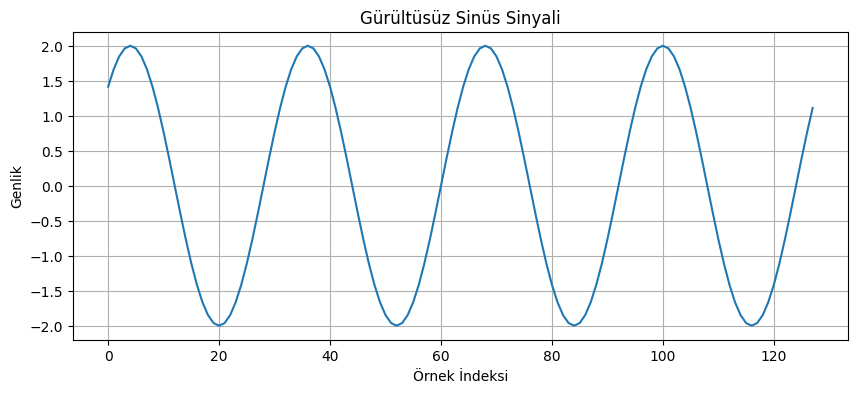

In [2]:
N = 128
n = np.arange(N)

genlik = 2
faz = np.pi / 4
periyot = 32

temiz = genlik * np.sin(
    2 * np.pi * n / periyot + faz
)

plt.figure(figsize=(10, 4))
plt.plot(n, temiz)
plt.title("Gürültüsüz Sinüs Sinyali")
plt.xlabel("Örnek İndeksi")
plt.ylabel("Genlik")
plt.grid(True)
plt.show()

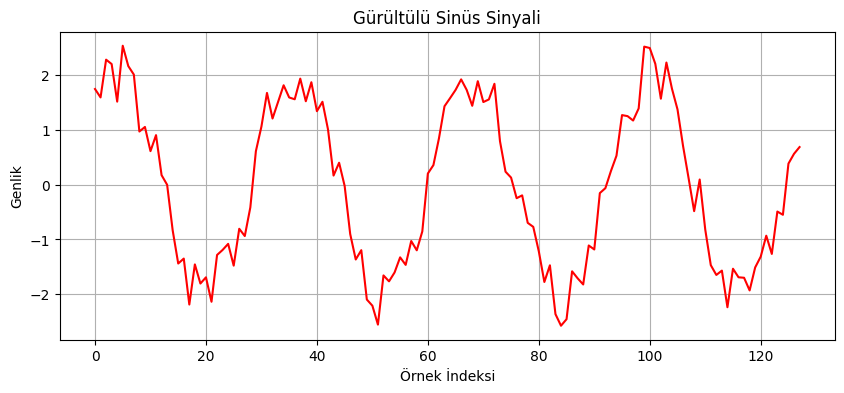

In [3]:
rng = np.random.default_rng(42)

gurultu_orani = 0.3
gurultu_genligi = np.max(np.abs(temiz)) * gurultu_orani

gurultu = rng.uniform(
    -gurultu_genligi,
    gurultu_genligi,
    size=N
)

gurultulu = temiz + gurultu

plt.figure(figsize=(10, 4))
plt.plot(n, gurultulu, color="red")
plt.title("Gürültülü Sinüs Sinyali")
plt.xlabel("Örnek İndeksi")
plt.ylabel("Genlik")
plt.grid(True)
plt.show()

In [4]:
def dft_hesapla(vektor):

    N = len(vektor)

    if N == 0 or (N & (N - 1)) != 0:
        raise ValueError("Vektör boyutu 2'nin kuvveti olmalıdır!")

    harmonikler = np.zeros(N, dtype=complex)

    for k in range(N):

        for n in range(N):

            harmonikler[k] += vektor[n] * np.exp(
                -2j * np.pi * k * n / N
            )

    return harmonikler

In [5]:
harmonik_temiz = dft_hesapla(temiz)
harmonik_gurultulu = dft_hesapla(gurultulu)

print("Gürültüsüz harmonik vektörü:")
print(harmonik_temiz)

print("\nGürültülü harmonik vektörü:")
print(harmonik_gurultulu)

Gürültüsüz harmonik vektörü:
[ 5.10702591e-15+0.00000000e+00j -4.44089210e-16-5.16947596e-15j
 -4.44089210e-15-1.66255898e-14j  1.70974346e-14-7.38298311e-15j
  9.05096680e+01-9.05096680e+01j -2.35367281e-14+2.78665979e-14j
 -2.22044605e-14-9.10382880e-15j -3.33066907e-14-3.84137167e-14j
 -2.66453526e-15+1.57651669e-14j -1.06581410e-14+8.43769499e-15j
 -5.88418203e-15-7.54951657e-15j -3.63042929e-14+1.22124533e-15j
 -1.67643677e-14-1.66533454e-15j  4.67403893e-14-2.30926389e-14j
  6.88338275e-15+9.12603326e-14j -2.47579734e-14+6.72795153e-14j
  6.66133815e-16-5.51780843e-14j -4.91828800e-14+3.51940699e-14j
  3.66373598e-15+4.66293670e-15j -5.28466160e-14+4.94049246e-14j
  7.41628980e-14+2.22044605e-15j -7.43849426e-15+5.71764858e-14j
 -2.47579734e-14-9.43689571e-15j  1.34336986e-14-3.08642001e-14j
 -4.22994972e-14+3.48610030e-14j  6.07291994e-14+8.77076189e-14j
 -5.05151476e-15-3.95239397e-14j -6.83897383e-14+1.10578213e-13j
 -7.51065876e-14+8.43769499e-14j -1.65450986e-13-3.30846461e-

In [6]:
def genlik_spektrumu(harmonikler):

    N = len(harmonikler)

    genlikler = np.abs(harmonikler[:N // 2 + 1]) / N

    genlikler[1:-1] *= 2

    return genlikler


genlik_temiz = genlik_spektrumu(harmonik_temiz)
genlik_gurultulu = genlik_spektrumu(harmonik_gurultulu)

frekanslar = np.arange(N // 2 + 1)

print("Harmonik sayısı:", len(genlik_temiz))

Harmonik sayısı: 65


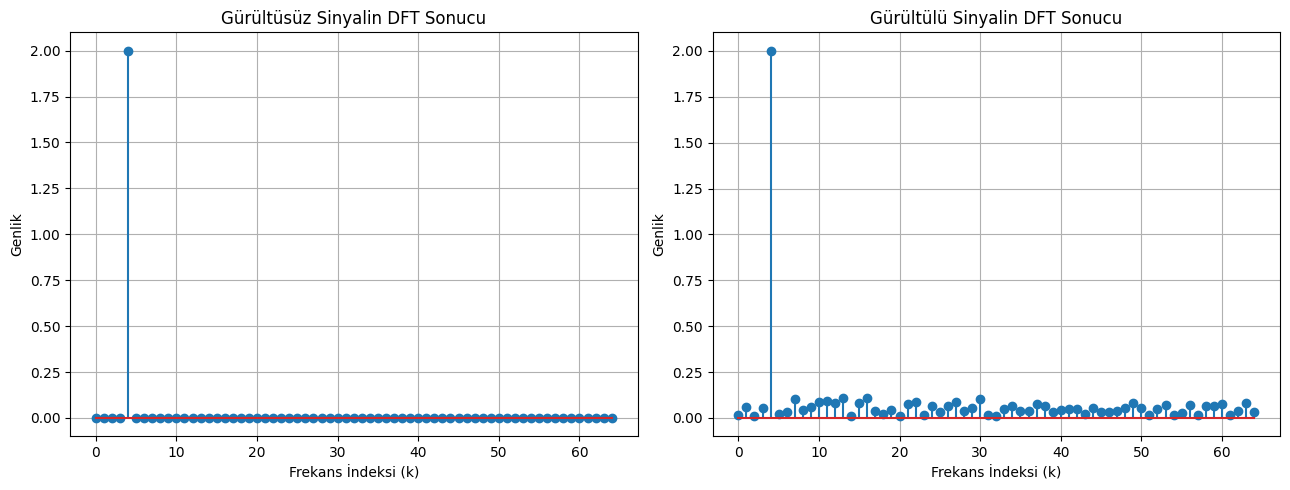

In [7]:
plt.figure(figsize=(13, 5))

plt.subplot(1, 2, 1)
plt.stem(frekanslar, genlik_temiz)
plt.title("Gürültüsüz Sinyalin DFT Sonucu")
plt.xlabel("Frekans İndeksi (k)")
plt.ylabel("Genlik")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.stem(frekanslar, genlik_gurultulu)
plt.title("Gürültülü Sinyalin DFT Sonucu")
plt.xlabel("Frekans İndeksi (k)")
plt.ylabel("Genlik")
plt.grid(True)

plt.tight_layout()
plt.savefig("odev34_dft_karsilastirma.png", dpi=200)
plt.show()

In [8]:
k_temiz = np.argmax(genlik_temiz)
k_gurultulu = np.argmax(genlik_gurultulu)

print("Gürültüsüz sinyal:")
print("En güçlü harmonik:", k_temiz)
print("Genlik:", round(genlik_temiz[k_temiz], 4))

print("\nGürültülü sinyal:")
print("En güçlü harmonik:", k_gurultulu)
print("Genlik:", round(genlik_gurultulu[k_gurultulu], 4))

Gürültüsüz sinyal:
En güçlü harmonik: 4
Genlik: 2.0

Gürültülü sinyal:
En güçlü harmonik: 4
Genlik: 2.0017


In [9]:
hazir_dft = np.fft.fft(temiz)

dogru_mu = np.allclose(
    harmonik_temiz,
    hazir_dft
)

print("Kendi DFT sonucumuz doğru mu?", dogru_mu)

Kendi DFT sonucumuz doğru mu? True


### Sonuç ve Yorum

Bu çalışmada 128 elemanlı gürültüsüz ve gürültülü sinüs sinyallerine DFT uygulanarak frekans bileşenleri incelenmiştir. DFT işlemi hazır bir fonksiyon kullanılmadan yazılmış ve elde edilen harmonik vektörleri grafiklerle karşılaştırılmıştır.

Gürültüsüz sinyalin frekans spektrumunda 4. harmonik indeksinde belirgin bir tepe oluşması beklenmektedir. Gürültülü sinyalde ise ana frekans bileşeni korunurken diğer frekanslarda da küçük genlikli bileşenler ortaya çıkmaktadır. Bu durum, gürültünün sinyalin frekans içeriğini etkilediğini göstermektedir.

DFT sayesinde zaman uzayında doğrudan görülemeyen frekans bileşenleri daha kolay incelenebilmektedir.